<a href="https://colab.research.google.com/github/JManuelRG/Procesos-de-Separacion/blob/main/Destilacion/McCabe_Thiele_Ejemplo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Método de McCabe-Thiele: Explicación y Ejemplo en Python

El **método de McCabe-Thiele** es una técnica gráfica clásica e intuitiva utilizada en ingeniería química para determinar el número de etapas teóricas de equilibrio necesarias en la separación de una mezcla binaria por destilación fraccionada.

---

## 1. Fundamentos del Método

El método asume el modelo de **desbordamiento equimolar** (los flujos molares de líquido y vapor se mantienen constantes en cada sección de la columna) y se basa en el balance de materia y el equilibrio de fases a presión constante.

### Componentes del Diagrama ($y-x$):

1. **Curva de Equilibrio Líquido-Vapor ($V-L$):**
   Relaciona la composición del vapor ($y$) con la del líquido ($x$) en equilibrio. Para sistemas ideales con volatilidad relativa constante ($\alpha$):
   $$y = \frac{\alpha x}{1 + (\alpha - 1)x}$$

2. **Línea Diagonal ($y = x$):**
   Sirve como referencia geométrica para los puntos de composición ($x_D$, $z_F$, $x_W$).

3. **Línea de Operación de Rectificación (ROL):**
   Modela la sección superior de la columna (por encima de la entrada de alimentación):
   $$y = \frac{R}{R+1}x + \frac{x_D}{R+1}$$
   donde $R$ es la relación de reflujo ($R = L/D$).

4. **Línea de Alimentación ($q$-line):**
   Representa el estado térmico de la corriente de entrada ($q$):
   $$y = \frac{q}{q-1}x - \frac{z_F}{q-1}$$
   * Si $q = 1$: Líquido saturado (línea vertical en $x = z_F$).
   * Si $q = 0$: Vapor saturado (línea horizontal en $y = z_F$).

5. **Línea de Operación de Agotamiento (SOL):**
   Modela la sección inferior de la columna. Conecta el punto de intersección entre la ROL y la $q$-line con el punto de fondos $(x_W, x_W)$ en la diagonal.

---

## 2. Planteamiento del Problema

Diseñar una columna de destilación continua para una mezcla binaria ideal con los siguientes datos de operación:

* **Volatilidad relativa ($\alpha$):** $2.5$
* **Composición de alimentación ($z_F$):** $0.40$ (fracción molar del componente más volátil)
* **Composición del destilado ($x_D$):** $0.96$
* **Composición de fondos ($x_W$):** $0.04$
* **Condición de alimentación ($q$):** $1.0$ (Líquido saturado)
* **Relación de reflujo ($R$):** $2.0$

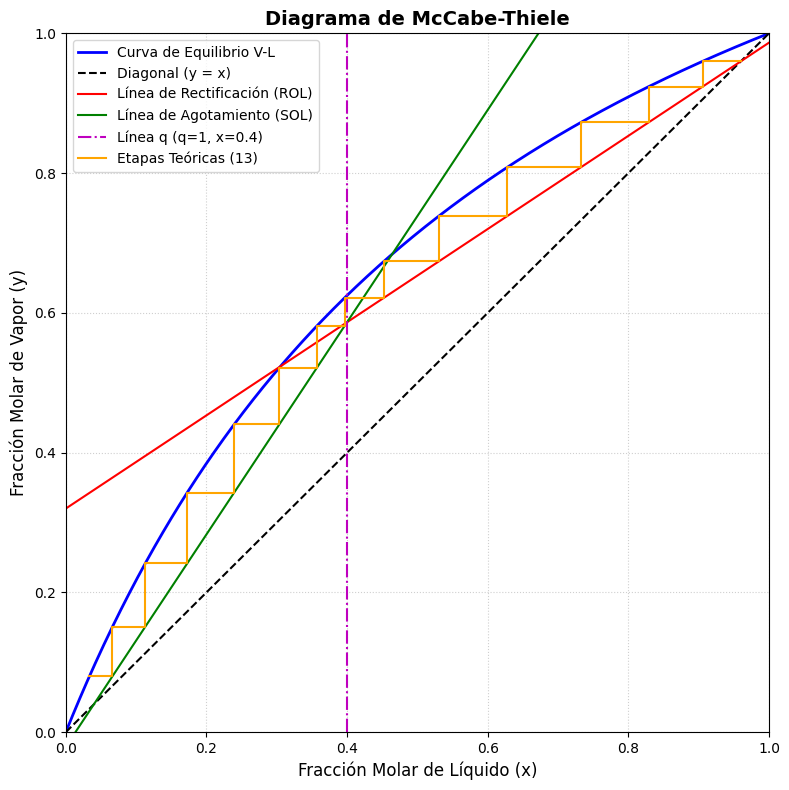

=== RESULTADOS DEL DISEÑO ===
Número total de etapas teóricas: 13
Plato óptimo de alimentación: 7 (contando desde el tope)
Relación de reflujo (R): 2.0


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. PARÁMETROS DEL SISTEMA
# ==========================================
alpha = 2.5       # Volatilidad relativa
z_F = 0.40        # Fracción molar de alimentación
xD = 0.96         # Fracción molar del destilado
xW = 0.04         # Fracción molar de fondos
q = 1.0           # Condición térmica (1.0 = líquido saturado)
R = 2.0           # Relación de reflujo

# ==========================================
# 2. CURVAS Y LÍNEAS DE OPERACIÓN
# ==========================================
# Curva de equilibrio V-L
x_eq = np.linspace(0, 1, 500)
y_eq = (alpha * x_eq) / (1 + (alpha - 1) * x_eq)

# Línea de operación de rectificación (ROL)
slope_rect = R / (R + 1)
intercept_rect = xD / (R + 1)

# Intersección de la línea q con la ROL -> Punto (x_int, y_int)
if q == 1:
    x_int = z_F
    y_int = slope_rect * x_int + intercept_rect
else:
    slope_q = q / (q - 1)
    intercept_q = -z_F / (q - 1)
    x_int = (intercept_rect - intercept_q) / (slope_q - slope_rect)
    y_int = slope_rect * x_int + intercept_rect

# Línea de operación de agotamiento (SOL)
slope_strip = (y_int - xW) / (x_int - xW)
intercept_strip = xW - slope_strip * xW

# ==========================================
# 3. CONSTRUCCIÓN DE ETAPAS (ESCALONES)
# ==========================================
x_curr = xD
y_curr = xD
stages = 0
feed_stage = None
passed_feed = False

escalones_x = [x_curr]
escalones_y = [y_curr]

while x_curr > xW and stages < 100:
    # Movimiento horizontal a la curva de equilibrio
    x_eq_val = y_curr / (alpha - (alpha - 1) * y_curr)
    escalones_x.extend([x_curr, x_eq_val])
    escalones_y.extend([y_curr, y_curr])

    x_curr = x_eq_val

    # Detección del plato de alimentación
    if not passed_feed and x_curr <= x_int:
        feed_stage = stages + 1
        passed_feed = True

    if x_curr <= xW:
        break

    # Movimiento vertical a la línea de operación correspondiente
    if x_curr > x_int:
        y_next = slope_rect * x_curr + intercept_rect
    else:
        y_next = slope_strip * x_curr + intercept_strip

    escalones_x.append(x_curr)
    escalones_y.append(y_next)

    y_curr = y_next
    stages += 1

total_stages = stages

# ==========================================
# 4. GRAFICACIÓN DE RESULTADOS
# ==========================================
plt.figure(figsize=(8, 8))

plt.plot(x_eq, y_eq, 'b-', label='Curva de Equilibrio V-L', linewidth=2)
plt.plot([0, 1], [0, 1], 'k--', label='Diagonal (y = x)')
plt.plot(x_eq, slope_rect * x_eq + intercept_rect, 'r-', label='Línea de Rectificación (ROL)', linewidth=1.5)
plt.plot(x_eq, slope_strip * x_eq + intercept_strip, 'g-', label='Línea de Agotamiento (SOL)', linewidth=1.5)

# Línea q
if q == 1:
    plt.axvline(x=z_F, color='m', linestyle='-.', label=f'Línea q (q=1, x={z_F})')
else:
    x_q_line = np.linspace(z_F, x_int, 100)
    y_q_line = (q / (q - 1)) * x_q_line - (z_F / (q - 1))
    plt.plot(x_q_line, y_q_line, 'm-.', label='Línea q')

# Escalones de etapas teóricas
plt.plot(escalones_x, escalones_y, color='orange', linestyle='-', label=f'Etapas Teóricas ({total_stages})', linewidth=1.5)

plt.title('Diagrama de McCabe-Thiele', fontsize=14, fontweight='bold')
plt.xlabel('Fracción Molar de Líquido (x)', fontsize=12)
plt.ylabel('Fracción Molar de Vapor (y)', fontsize=12)
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

# ==========================================
# 5. REPORTE DE RESULTADOS
# ==========================================
print("=== RESULTADOS DEL DISEÑO ===")
print(f"Número total de etapas teóricas: {total_stages}")
print(f"Plato óptimo de alimentación: {feed_stage} (contando desde el tope)")
print(f"Relación de reflujo (R): {R}")